# 05 — İşleme Performansı: pandas vs PySpark × CSV vs Parquet (Öğrenci 5)

**Araştırma sorusu:** Veri büyüdükçe klasik analiz yaklaşımı (tek makinede pandas + CSV) ne zaman yetersiz kalıyor?

Öğrenci 1 **okumayı** ölçtü (`io_benchmark.csv`). Bu notebook **işlemeyi** ölçer: 3 ileri analitik işlem × 2 motor × 2 format × 5 veri boyutu.

| İşlem | Ne yapar | Analitik tür |
|---|---|---|
| `groupby_hour` | Saate göre yolculuk sayısı, ort. mesafe, ort. ücret, toplam gelir | aggregation |
| `join_borough` | Yolculuklar ⋈ bölge tablosu (265 satır) → ilçeye göre özet | join |
| `window_top3` | Her biniş bölgesinde en yüksek tutarlı 3 yolculuk (`row_number`) | window |

Ölçümün tamamı `python -m src.benchmark_processing` ile çalışır (~10 dk). Bu notebook önce iki motorun aynı sonucu verdiğini canlı gösterir, sonra kayıtlı ölçümleri yorumlar.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src import config
from src import benchmark_processing as bp
from src import plots_processing as pp
from src.build_sizes import target_path
pd.set_option("display.width", 160)

## 1. Aynı işlem, iki motor (canlı, 1M kayıt, Parquet)

İki motor aynı sonucu vermiyorsa hız karşılaştırması anlamsızdır. Benchmark her ölçümde satır sayısı ve checksum kaydeder; burada üç işlemi elle çalıştırıp sonuçları yan yana koyuyoruz.

In [2]:
from src.spark_session import get_spark

path = target_path(config.PROCESSED_DIR, "1m", "parquet_snappy")
pdf = bp.pandas_load(path)
zones = bp.pandas_zones()

spark = get_spark(app_name="s5-notebook")
schema = spark.read.parquet(str(path)).schema
sdf = bp.spark_frame(spark, path, "parquet_snappy", schema)
s_zones = bp.spark_zones(spark)

rows = []
for op in bp.OPERATIONS:
    p_fn, col = bp.pandas_ops(zones)[op]
    s_fn, _ = bp.spark_ops(s_zones)[op]
    p = bp.checksum(p_fn(pdf), col)
    s = bp.checksum(s_fn(sdf).toPandas(), col)
    rows.append({"işlem": op, "pandas satır": p[0], "Spark satır": s[0],
                 "pandas checksum": round(p[1], 2), "Spark checksum": round(s[1], 2)})
spark.stop()
pd.DataFrame(rows)

,işlem,pandas satır,Spark satır,pandas checksum,Spark checksum
0,groupby_hour,24,24,1000051.00,1000051.00
1,join_borough,8,8,1000051.00,1000051.00
2,window_top3,762,762,125164.42,125164.42


In [3]:
# Örnek çıktı: ilçeye göre özet (join)
bp.pandas_join_borough(pdf, zones).sort_values("trips", ascending=False)

,Borough,trips,avg_total
3,Manhattan,859521,26.010983
5,Queens,88433,64.358566
1,Brooklyn,40506,36.049442
0,Bronx,9757,37.510662
7,Unknown,1173,32.550494
4,N/A,419,102.254654
6,Staten Island,123,46.817398
2,EWR,119,96.841429


## 2. Kayıtlı ölçümler ve tutarlılık

In [4]:
summary = pd.read_csv(config.RESULTS_DIR / bp.SUMMARY_FILE)
print("Tutarsızlık:", bp.check_consistency(summary) or "yok — 5 boyut × 3 işlemde 4 kombinasyon aynı sonucu verdi")
pivot = summary.pivot_table(index=["op", "engine", "format"], columns="size", values="seconds_mean")
pivot[["100k", "1m", "5m", "10m", "full"]].round(3)

Tutarsızlık: yok — 5 boyut × 3 işlemde 4 kombinasyon aynı sonucu verdi


size                                 100k     1m     5m     10m    full
op           engine format                                             
groupby_hour pandas csv             0.007  0.039  0.192   0.369   0.697
                    parquet_snappy  0.007  0.036  0.186   0.353   0.697
             spark  csv             0.306  0.754  1.624   2.880   5.862
                    parquet_snappy  0.242  0.312  0.641   0.736   0.912
join_borough pandas csv             0.014  0.110  0.530   1.050   1.972
                    parquet_snappy  0.016  0.112  0.541   1.079   2.125
             spark  csv             0.238  0.516  1.111   1.909   4.205
                    parquet_snappy  0.244  0.297  0.509   0.573   0.708
load         pandas csv             0.130  1.092  5.364  10.280  18.818
                    parquet_snappy  0.015  0.028  0.094   0.170   0.367
startup      spark  csv             5.695  5.589  5.663   5.562   5.478
                    parquet_snappy  5.484  5.557  5.492   5.518   5.813
window_top3  pandas csv             0.009  0.101  0.493   1.032   2.074
                    parquet_snappy  0.008  0.096  0.486   1.006   2.089
             spark  csv             0.573  2.469  3.566   4.764   6.623
                    parquet_snappy  0.483  1.058  3.920   5.059   6.095

In [5]:
# Ölçüm kararlılığı: varyasyon katsayısı (std / ortalama), işlemler için
ops = summary[summary["op"].isin(bp.OPERATIONS)].copy()
ops["cv_%"] = (100 * ops["seconds_std"] / ops["seconds_mean"]).round(1)
ops.groupby(["engine", "format"])["cv_%"].describe()[["mean", "50%", "max"]]

mean  50%   max
engine format                             
pandas csv             2.606667  1.3  10.8
       parquet_snappy  3.266667  2.3  13.5
spark  csv             5.226667  5.0  15.8
       parquet_snappy  5.893333  5.8  12.5

## 3. İşlem süresi

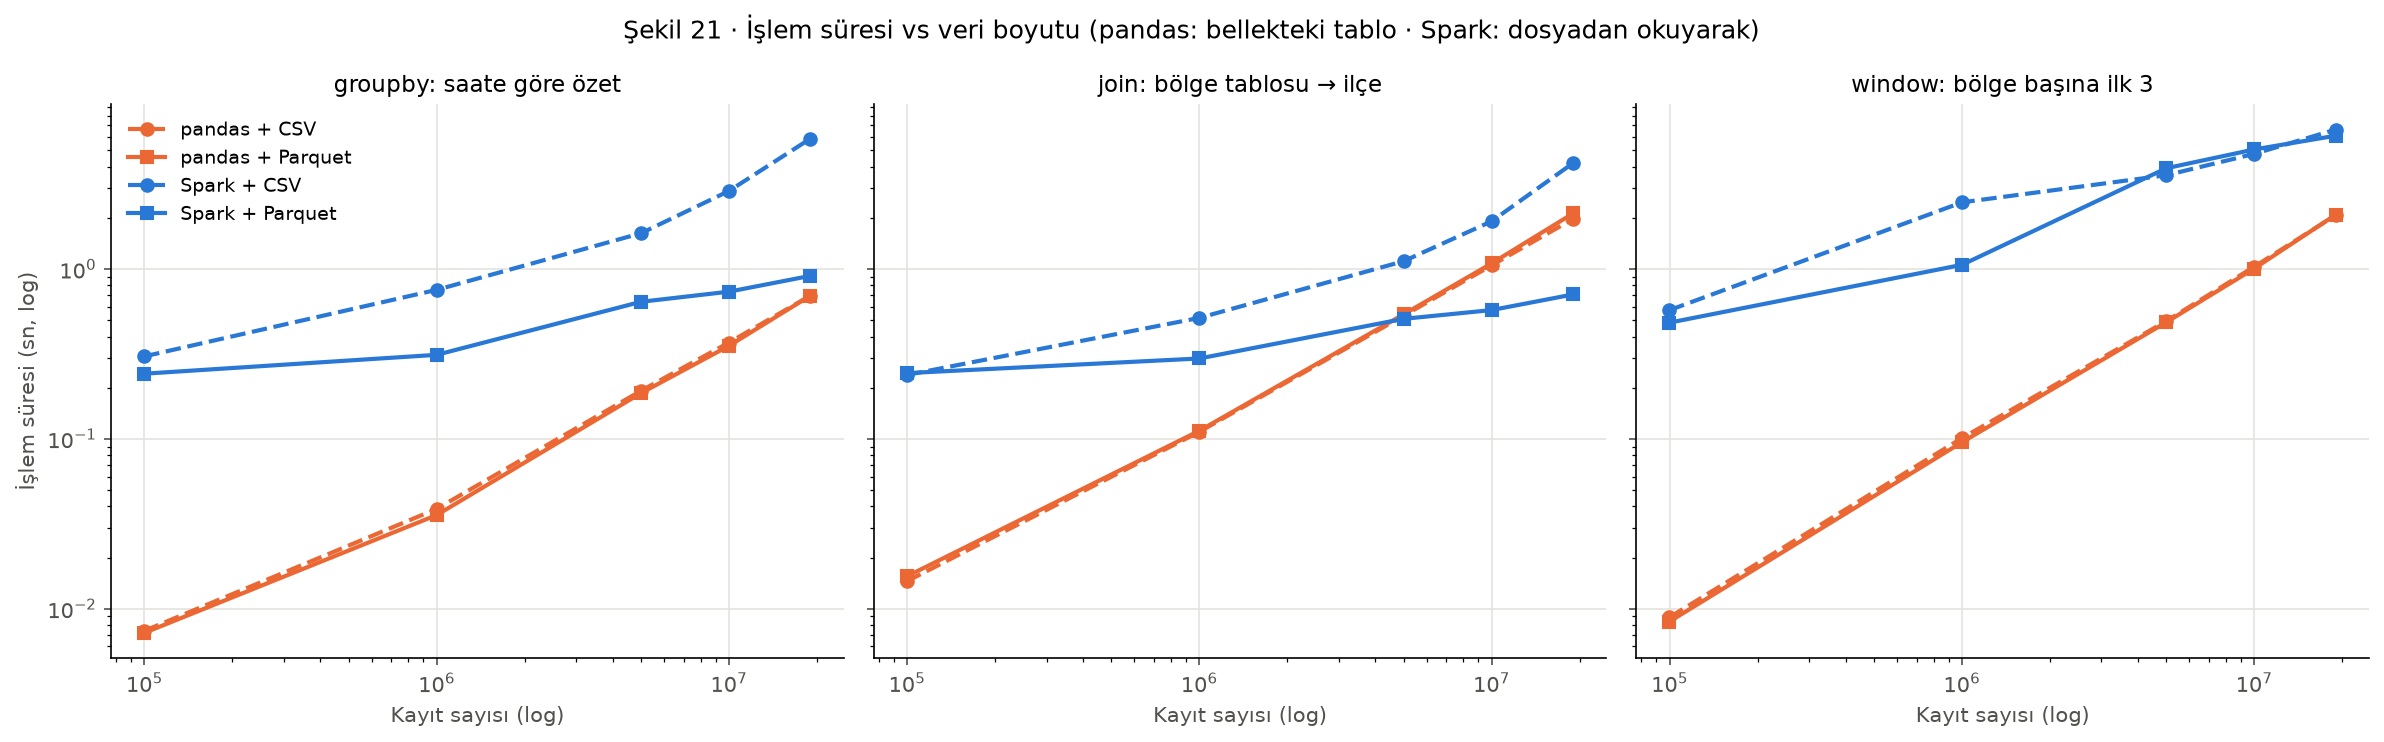

,csv,parquet_snappy
groupby_hour,—,—
join_borough,—,4.5M
window_top3,—,—


In [6]:
display(Image(filename=str(config.FIGURES_DIR / "21_s5_op_time.png")))
cross = {op: {f: pp.crossover_rows(summary[summary.op == op], f, "seconds_mean") for f in pp.FORMAT_STYLE} for op in bp.OPERATIONS}
pd.DataFrame(cross).T.map(lambda v: "—" if pd.isna(v) else f"{v/1e6:.1f}M")

Tablo: Spark'ın işlem bazında pandas'ı geçtiği kayıt sayısı ("—" = 19M'e kadar geçmiyor).

In [7]:
# Ölçeklenme: 100K → 19M (190× veri) süre artış katı
grow = summary[summary["op"].isin(bp.OPERATIONS)].pivot_table(index=["op", "engine", "format"], columns="size", values="seconds_mean")
(grow["full"] / grow["100k"]).round(1).rename("süre artışı (×)").to_frame()

süre artışı (×)
op           engine format                         
groupby_hour pandas csv                        94.2
                    parquet_snappy             96.8
             spark  csv                        19.2
                    parquet_snappy              3.8
join_borough pandas csv                       136.0
                    parquet_snappy            137.1
             spark  csv                        17.7
                    parquet_snappy              2.9
window_top3  pandas csv                       233.0
                    parquet_snappy            248.7
             spark  csv                        11.6
                    parquet_snappy             12.6

## 4. Uçtan uca süre ve bellek

rows                   99839     1000051   4997943   9996122   18999282
engine format                                                          
pandas csv                 0.16      1.34      6.58     12.73     23.56
       parquet_snappy      0.05      0.27      1.31      2.61      5.28
spark  csv                 6.81      9.33     11.96     15.11     22.17
       parquet_snappy      6.45      7.23     10.56     11.89     13.53

csv: Spark uçtan uca öne geçer → ≈ 16.1M kayıt
parquet_snappy: Spark uçtan uca öne geçer → 19M'e kadar geçmiyor


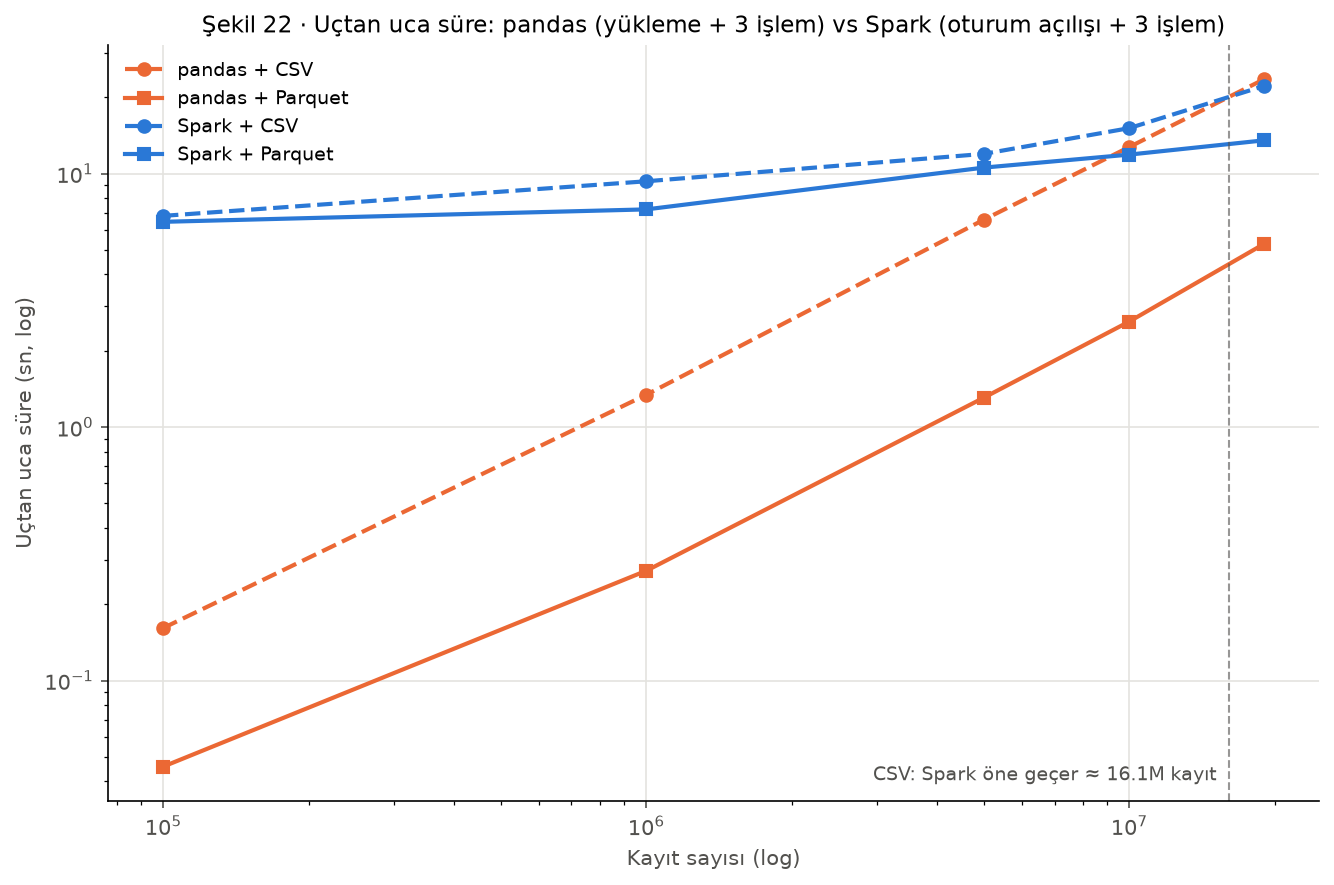

In [8]:
e2e = bp.end_to_end(summary)
display(e2e.pivot_table(index=["engine", "format"], columns="rows", values="total_s").round(2))
for f in pp.FORMAT_STYLE:
    x = pp.crossover_rows(e2e, f)
    print(f"{f}: Spark uçtan uca öne geçer →", "19M'e kadar geçmiyor" if x is None else f"≈ {x/1e6:.1f}M kayıt")
display(Image(filename=str(config.FIGURES_DIR / "22_s5_end_to_end.png")))

rows                   99839     1000051   4997943   9996122   18999282
engine format                                                          
pandas csv                111.0     228.0     723.0    1273.0    2721.0
       parquet_snappy     123.0     268.0    1318.0    2075.0    3147.0
spark  csv                968.0    2254.0    2514.0    3280.0    4940.0
       parquet_snappy     800.0    1073.0    2054.0    2692.0    4205.0

pandas + csv: 0.140 KB/kayıt → 238M kayıtta RAM dolar (doğrusal ekstrapolasyon)
pandas + parquet_snappy: 0.165 KB/kayıt → 202M kayıtta RAM dolar (doğrusal ekstrapolasyon)


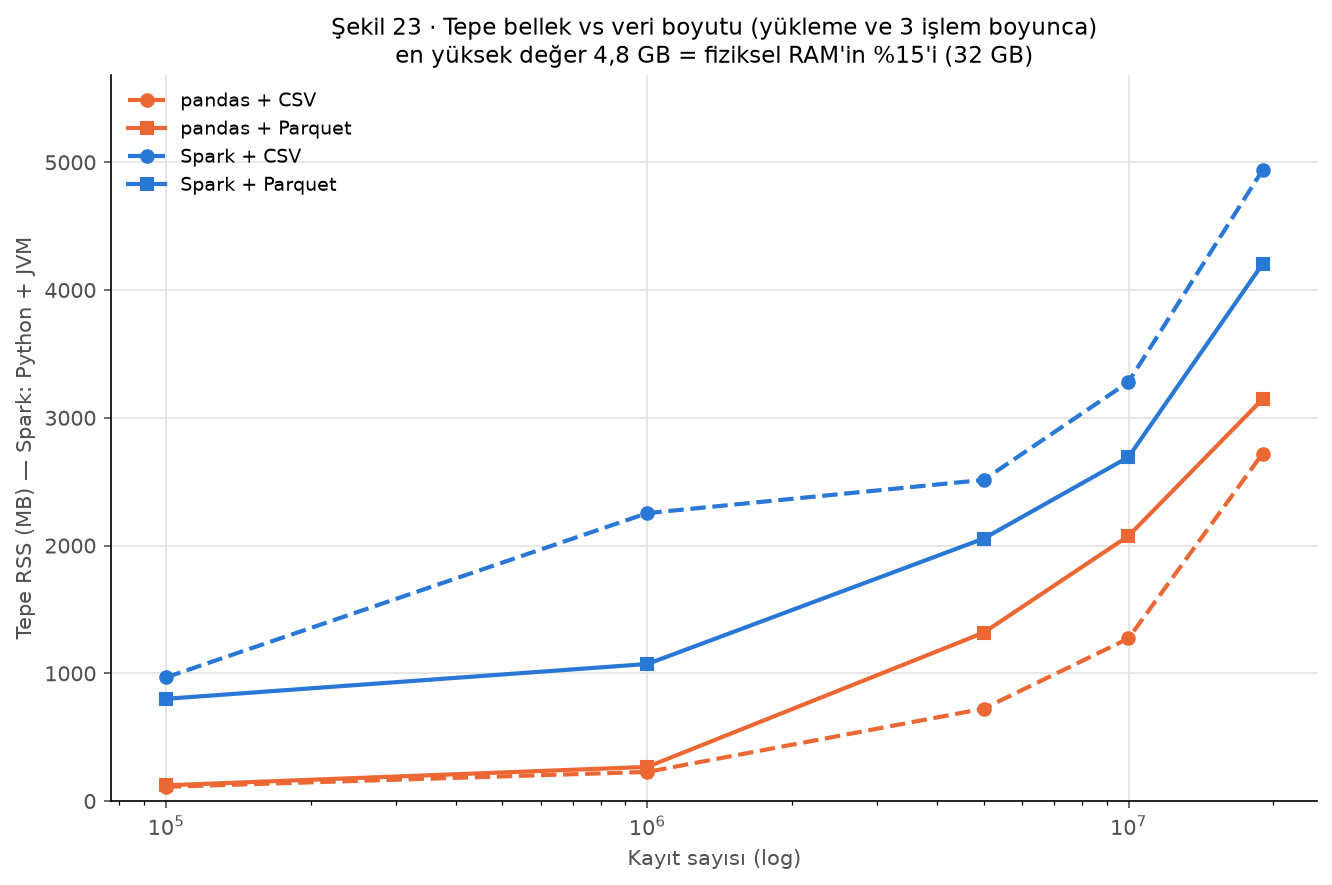

In [9]:
display(e2e.pivot_table(index=["engine", "format"], columns="rows", values="peak_rss_mb").round(0))
slopes = pp.memory_per_row_kb(summary)
import psutil
ram_mb = psutil.virtual_memory().total / 1024**2
for f, kb in slopes.items():
    print(f"pandas + {f}: {kb:.3f} KB/kayıt → {ram_mb / (kb / 1024) / 1e6:.0f}M kayıtta RAM dolar (doğrusal ekstrapolasyon)")
display(Image(filename=str(config.FIGURES_DIR / "23_s5_memory.png")))

## 5. Yorum — neden böyle?

- **Sabit maliyet ile doğrusal maliyet.** Spark'ın oturum açılışı ~5,5 sn, işlem başına planlama + görev başlatma ~0,25 sn sabit. pandas'ta sabit maliyet yok ama süre kayıtla doğrusal artıyor (tek çekirdek). Veri 190× büyürken pandas groupby 100×, Spark + Parquet groupby 3,8× yavaşlıyor. Küçük veride pandas, büyük veride Spark avantajlı. Kesişim noktası işleme göre değişiyor.
- **Format, motordan daha belirleyici.** Spark tembel çalışıyor ve her işlemde dosyayı yeniden okuyor. CSV her seferinde tümüyle parse ediliyor (groupby 19M: CSV 5,9 sn vs Parquet 0,9 sn). pandas CSV maliyetini bir kez, yüklemede ödüyor ama bu maliyet büyük: 18,8 sn (~1M kayıt/sn). Parquet'ten yükleme 0,37 sn.
- **join: Spark kazanıyor.** Broadcast hash join + kısmi toplama 20 iş parçacığında tek aşamada çalışıyor ve birleşik tabloyu hiç oluşturmuyor. pandas `merge` 19M satırlık bir kopya oluşturup sonra grupluyor.
- **window: pandas kazanıyor.** `partitionBy` tüm verinin shuffle edilmesini (diske yaz + oku) ve her bölümde sıralamayı gerektiriyor; en yoğun bölge verinin %4,7'sini tek göreve yüklüyor. pandas tek bir vektörel sıralama yapıyor.
- **Bellek.** Spark'ın JVM tabanı ~0,5 GB ve window shuffle'ı 19M'de 4–5 GB'a çıkıyor. pandas 19M'de 2,7–3,1 GB kullanıyor ve kayıtla doğrusal artıyor.

## 6. Araştırma sorusuna cevap

1. **pandas + CSV, ~16M kayıtta Spark + CSV'nin, ~9M kayıtta Spark + Parquet'in gerisine düşüyor.** Darboğaz tek çekirdekli CSV parse.
2. **Formatı değiştirmek (CSV → Parquet) motoru değiştirmekten daha büyük kazanç sağlıyor.** pandas + Parquet 19M'de bile en hızlı seçenek (uçtan uca 5,3 sn; Spark + Parquet 13,5 sn).
3. **"Yetersizlik" işleme bağlı.** join'de Spark 4,5M'den itibaren önde; window'da 19M'de hâlâ 3× geride.
4. **Klasik yaklaşımın sert sınırı bellek.** Bu makinede 6 kolonla ~200M, tüm kolonlarla ~65M kayıt. Bu noktadan sonra Spark (diske taşma, dağıtım) zorunlu hale gelir.

**Sınırlamalar:** Tek makine (`local[*]`). Spark'ta `cache()` senaryosu ölçülmedi. Bellek sınırları ekstrapolasyon. Sıcak işletim sistemi önbelleği. S1'in okuma ölçümleri farklı bir makinede alındı.